## Generating the delayed ENSO signal


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.linear_model import Lasso

kappa = 1.5
delta = 1.0
dt = 0.001
T = 60
sigma = 0.5
win = 0.1
spinup = int(10 / dt)
train_frac = 0.7
alpha = 0.2
beta = 1e-8

In [2]:
def rk4vec_ext(u0,t0,dt,f,args):
    k1=dt*f(u0,t0,*args)
    k2=dt*f(u0+k1/2,t0+dt/2,*args)
    k3=dt*f(u0+k2/2,t0+dt/2,*args)
    k4=dt*f(u0+k3,t0+dt,*args)
    return u0+(k1+2*k2+2*k3+k4)/6


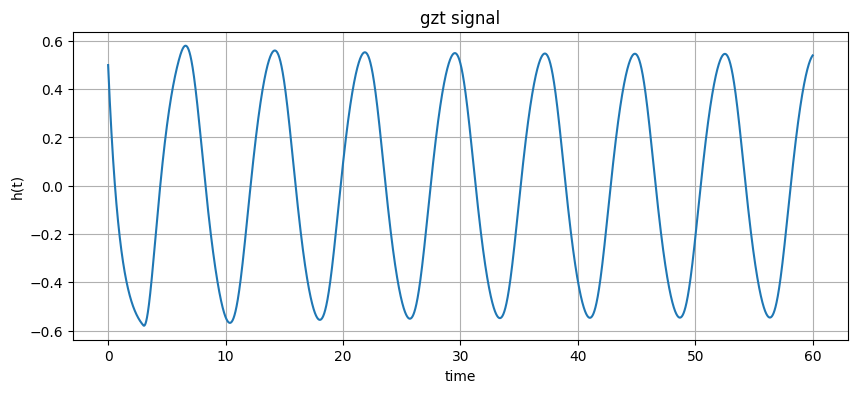

In [3]:
def simulate_gzt(kappa,tau,dt,T,delta=1.0):
    n_steps=int(T/dt)
    n_delay=int(round(tau/dt))
    # store the past values of h
    h=np.zeros(n_steps+n_delay+1)
    # history before t=0
    h[:n_delay+1]=0.5

    def delayed_value(index,offset):
        x=index-n_delay+offset
        i0=int(np.floor(x))
        frac=x-i0
        if i0<0:
            return 0.5
        return (1-frac)*h[i0]+frac*h[i0+1]

    for i in range(n_delay,n_delay+n_steps):
        hc=h[i]
        d1=-delta*hc-np.tanh(kappa*delayed_value(i,0))
        h2=hc+dt*d1/2
        d2=-delta*h2-np.tanh(kappa*delayed_value(i,0.5))
        h3=hc+dt*d2/2
        d3=-delta*h3-np.tanh(kappa*delayed_value(i,0.5))
        h4=hc+dt*d3
        d4=-delta*h4-np.tanh(kappa*delayed_value(i,1))
        h[i+1]=hc+dt*(d1+2*d2+2*d3+d4)/6

    time=np.arange(n_steps)*dt
    return time,h[n_delay:n_delay+n_steps]

# test the gzt model
tau=3.0
time,h=simulate_gzt(kappa,tau,dt,T,delta)

# plot the signal
plt.figure(figsize=(10,4))
plt.plot(time,h)
plt.xlabel("time")
plt.ylabel("h(t)")
plt.title("gzt signal")
plt.grid()
plt.show()

## Clean chain reservoir and delay reconstruction

In [4]:
# prepare the delayed target
data=h.reshape(-1,1)

train_len=int(train_frac*len(data))
delay_steps=int(round(tau/dt))
start=max(spinup,delay_steps)

y_train=data[start-delay_steps:train_len-delay_steps,0]
y_test=data[train_len-delay_steps:len(data)-delay_steps,0]

print("training points:",len(y_train))
print("test points:",len(y_test))

training points: 32000
test points: 18000


In [ ]:
def chain_reservoir(r,t,u,gamma,sigma,win):
    z=np.empty_like(r)
    # current h(t) goes into the first neuron
    z[0]=sigma*win*u[0]
    # each neuron gets the previous neuron's value
    z[1:]=r[:-1]
    return gamma*(-r+np.tanh(z))

In [ ]:
def run_chain(data,N,gamma,sigma,win,dt):
    r=np.zeros(N)
    R=np.zeros((len(data),N))
    for i in range(len(data)):
        R[i]=r.copy()
        u=data[i].reshape(-1)
        r=rk4vec_ext(r,i*dt,dt,chain_reservoir,[u,gamma,sigma,win])
    return R

In [6]:
def scan_single_nodes(R_train,y_train,R_test,y_test,beta=1e-8):
    N=R_train.shape[1]
    nrmses=np.zeros(N)

    for j in range(N):
        x=R_train[:,j]
        w=(x@y_train)/(x@x+beta)
        prediction=w*R_test[:,j]
        rmse=np.sqrt(np.mean((prediction-y_test)**2))
        nrmses[j]=rmse/np.std(y_test)

    best_node=np.argmin(nrmses)
    return best_node,nrmses

tau: 3.0
gamma: 10
k: 30
expected neuron: 29
best neuron: 29
validation nrmse: 0.016887479037210922
test nrmse: 0.01669551021121488
single weight: 22.24910190771135


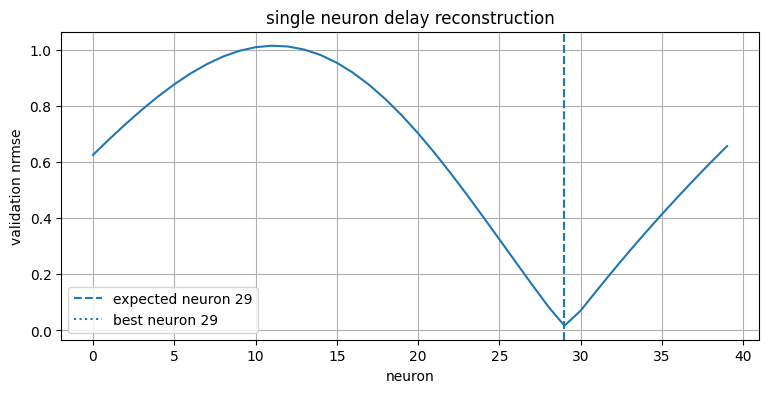

In [7]:
# choose gamma
gamma=10

# number of lct stages for tau
k=int(round(tau*gamma))

# python starts counting from 0
expected=k-1

# make the chain slightly longer than the delay
N=int(round((tau+1)*gamma))

# run h(t) through the reservoir chain
R=run_chain(data,N,gamma,sigma,win,dt)

# split the reservoir states into training and testing
R_train=R[start:train_len]
R_test=R[train_len:]

# keep the last 20% of training data for validation
split=int(0.8*len(y_train))
R_fit=R_train[:split]
y_fit=y_train[:split]
R_val=R_train[split:]
y_val=y_train[split:]

# find the best single neuron using validation data
best_node,nrmses=scan_single_nodes(R_fit,y_fit,R_val,y_val,beta)

# refit the selected neuron using all training data
x=R_train[:,best_node]
w=(x@y_train)/(x@x+beta)

# test the selected neuron
single_pred=w*R_test[:,best_node]
test_nrmse=np.sqrt(np.mean((single_pred-y_test)**2))/np.std(y_test)

print("tau:",tau)
print("gamma:",gamma)
print("k:",k)
print("expected neuron:",expected)
print("best neuron:",best_node)
print("validation nrmse:",nrmses[best_node])
print("test nrmse:",test_nrmse)
print("single weight:",w)

# plot the validation error for every neuron
plt.figure(figsize=(9,4))
plt.plot(np.arange(N),nrmses)

# mark the expected lct neuron
plt.axvline(expected,linestyle="--",label=f"expected neuron {expected}")

# mark the best neuron found
plt.axvline(best_node,linestyle=":",label=f"best neuron {best_node}")

plt.xlabel("neuron")
plt.ylabel("validation nrmse")
plt.title("single neuron delay reconstruction")
plt.legend()
plt.grid()
plt.show()

## LCT and LASSO readout experiments

In [8]:
def train_lasso(R,y,alpha):
    scales=np.std(R,axis=0)
    scales[scales<1e-12]=1.0
    yscale=np.std(y)

    X=R/scales
    yn=y/yscale

    model=Lasso(alpha=alpha,fit_intercept=False,max_iter=100000)
    model.fit(X,yn)

    Wscaled=model.coef_
    Wout=Wscaled*yscale/scales

    return Wout,Wscaled

# train the output weights
Wout,Wscaled=train_lasso(R_train,y_train,alpha)

# use all neurons together
prediction=R_test@Wout

# calculate the error
multi_nrmse=np.sqrt(np.mean((prediction-y_test)**2))/np.std(y_test)

# find which neurons lasso kept
selected=np.where(np.abs(Wscaled)>1e-10)[0]

print("best single neuron:",best_node)
print("best single nrmse:",nrmses[best_node])
print("multi-node nrmse:",multi_nrmse)
print("selected neurons:",selected)
print("number selected:",len(selected))

best single neuron: 29
best single nrmse: 0.016887479037210922
multi-node nrmse: 0.20159241069924938
selected neurons: [29]
number selected: 1


In [9]:
# try a broader delay memory
gamma=2

k=int(round(tau*gamma))
expected=k-1
N=int(round((tau+1)*gamma))

R=run_chain(data,N,gamma,sigma,win,dt)

R_train=R[start:train_len]
R_test=R[train_len:]

best_node,nrmses=scan_single_nodes(R_train,y_train,R_test,y_test,beta)

Wout,Wscaled=train_lasso(R_train,y_train,alpha)

prediction=R_test@Wout
multi_nrmse=np.sqrt(np.mean((prediction-y_test)**2))/np.std(y_test)

selected=np.where(np.abs(Wscaled)>1e-10)[0]

print("expected neuron:",expected)
print("best single neuron:",best_node)
print("best single nrmse:",nrmses[best_node])
print("multi-node nrmse:",multi_nrmse)
print("selected neurons:",selected)
print("number selected:",len(selected))
print("selected weights:",Wout[selected])

expected neuron: 5
best single neuron: 5
best single nrmse: 0.12516574398818156
multi-node nrmse: 0.20544160741740972
selected neurons: [5 6]
number selected: 2
selected weights: [18.75120251  7.66933601]


In [10]:
# try different gamma values
for gamma in [1,1.5,2,3,4,5,10]:
    k=int(round(tau*gamma))
    N=int(round((tau+1)*gamma))

    R=run_chain(data,N,gamma,sigma,win,dt)
    R_train=R[start:train_len]
    R_test=R[train_len:]

    best,nrmses=scan_single_nodes(R_train,y_train,R_test,y_test,beta)
    Wout,Wscaled=train_lasso(R_train,y_train,alpha)

    prediction=R_test@Wout
    multi=np.sqrt(np.mean((prediction-y_test)**2))/np.std(y_test)

    selected=np.where(np.abs(Wscaled)>1e-10)[0]

    print("gamma:",gamma)
    print("best single nrmse:",nrmses[best])
    print("multi nrmse:",multi)
    print("selected:",selected)
    print("weights:",Wout[selected])
    print()

gamma: 1
best single nrmse: 0.2847144899376932
multi nrmse: 0.21567169309929318
selected: [2 3]
weights: [14.57011246 27.92111844]

gamma: 1.5
best single nrmse: 0.051757966871046654
multi nrmse: 0.20946059544096388
selected: [4]
weights: [30.73650544]

gamma: 2
best single nrmse: 0.12516574398818156
multi nrmse: 0.20544160741740972
selected: [5 6]
weights: [18.75120251  7.66933601]

gamma: 3
best single nrmse: 0.06330818096772538
multi nrmse: 0.20319998463195685
selected: [8 9]
weights: [18.98265394  3.39611959]

gamma: 4
best single nrmse: 0.04128307408706474
multi nrmse: 0.20237172368304607
selected: [11 12]
weights: [18.90744734  1.69629492]

gamma: 5
best single nrmse: 0.031317471590628684
multi nrmse: 0.20199080920428222
selected: [14 15]
weights: [18.80270832  0.80974679]

gamma: 10
best single nrmse: 0.01669551021121488
multi nrmse: 0.20159241069924938
selected: [29]
weights: [17.80217954]



In [11]:
# use the case where 3 neurons were selected
gamma=4
k=int(tau*gamma)
N=int((tau+1)*gamma)

R=run_chain(data,N,gamma,sigma,win,dt)
R_train=R[start:train_len]
R_test=R[train_len:]

best_node,nrmses=scan_single_nodes(R_train,y_train,R_test,y_test,beta)
Wout,Wscaled=train_lasso(R_train,y_train,alpha)

selected=np.where(np.abs(Wscaled)>1e-10)[0]

print("expected neuron:",k-1)
print("selected neurons:",selected)
print("selected stages:",selected+1)
print("wout weights:",Wout[selected])

expected neuron: 11
selected neurons: [11 12]
selected stages: [12 13]
wout weights: [18.90744734  1.69629492]


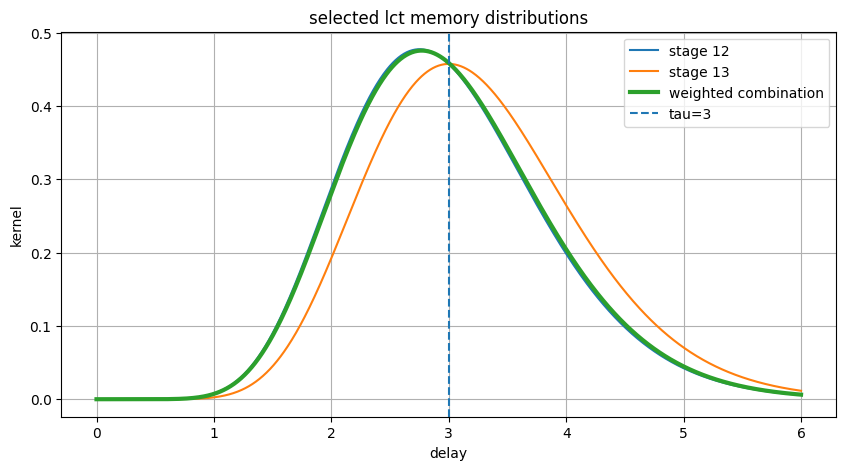

In [12]:
from math import factorial

# time into the past
s=np.linspace(0,6,1000)

stages=selected+1
weights=Wout[selected]

kernels=[]

# make the distribution for each selected stage
for stage in stages:
    K=(gamma**stage)*(s**(stage-1))*np.exp(-gamma*s)/factorial(stage-1)
    kernels.append(K)

kernels=np.array(kernels)

# add the distributions using the wout weights
combined=np.zeros_like(s)
for i in range(len(stages)):
    combined+=weights[i]*kernels[i]

# normalise so we compare the shape
combined=combined/np.trapezoid(combined,s)

# plot the individual distributions
plt.figure(figsize=(10,5))
for i in range(len(stages)):
    plt.plot(s,kernels[i],label=f"stage {stages[i]}")

plt.plot(s,combined,linewidth=3,label="weighted combination")
plt.axvline(tau,linestyle="--",label="tau=3")
plt.xlabel("delay")
plt.ylabel("kernel")
plt.title("selected lct memory distributions")
plt.legend()
plt.grid()
plt.show()

In [13]:
for i in range(len(stages)):
    mean=np.trapezoid(s*kernels[i],s)
    var=np.trapezoid((s-mean)**2*kernels[i],s)
    print("stage",stages[i],"width:",np.sqrt(var))

mean=np.trapezoid(s*combined,s)
var=np.trapezoid((s-mean)**2*combined,s)

print("combined mean:",mean)
print("combined width:",np.sqrt(var))

stage 12 width: 0.8485432989161465
stage 13 width: 0.8696579721598924
combined mean: 3.0111561882917264
combined width: 0.8540054107087575


ER NETWORK


In [14]:
def build_er_network(N,p,win,seed):
    rng=np.random.default_rng(seed)
    order=rng.permutation(N)
    rows=[]
    cols=[]

    # make random forward connections
    for j in range(1,N):
        target=order[j]
        possible=order[:j]
        chosen=possible[rng.random(j)<p]

        for source in chosen:
            rows.append(target)
            cols.append(source)

    # put the connections into a matrix
    A=sparse.csr_matrix((np.ones(len(rows)),(rows,cols)),shape=(N,N))

    # only one neuron gets h(t)
    Win=np.zeros(N)
    input_node=order[0]
    Win[input_node]=win

    return A,Win,input_node

In [15]:
def network_reservoir(r,t,u,gamma,sigma,A,Win):
    return gamma*(-r+np.tanh(A@r+sigma*Win*u[0]))

def run_network(data,A,Win,gamma,sigma,dt):
    N=A.shape[0]
    r=np.zeros(N)
    R=np.zeros((len(data),N))

    for i in range(len(data)):
        R[i]=r.copy()
        u=data[i].reshape(-1)
        r=rk4vec_ext(r,i*dt,dt,network_reservoir,[u,gamma,sigma,A,Win])

    return R

In [16]:
# random network settings
gamma=5
N=500
p=0.015
seed=1

# build and run the er network
A,Win,input_node=build_er_network(N,p,win,seed)

R_er=run_network(data,A,Win,gamma,sigma,dt)

# split reservoir states
R_er_train=R_er[start:train_len]
R_er_test=R_er[train_len:]

# choose the best single neuron using validation
split=int(0.8*len(y_train))

best_node,nrmses=scan_single_nodes(
    R_er_train[:split],y_train[:split],
    R_er_train[split:],y_train[split:],beta
)

# refit the chosen neuron using all training data
x=R_er_train[:,best_node]
w=(x@y_train)/(x@x+beta)

single_pred=w*R_er_test[:,best_node]

single_nrmse=np.sqrt(
    np.mean((single_pred-y_test)**2)
)/np.std(y_test)

# train the multi-neuron readout
Wout_er,Wscaled_er=train_lasso(
    R_er_train,y_train,alpha
)

multi_pred=R_er_test@Wout_er

multi_nrmse=np.sqrt(
    np.mean((multi_pred-y_test)**2)
)/np.std(y_test)

# find the neurons kept by lasso
selected=np.where(
    np.abs(Wscaled_er)>1e-10
)[0]

print("p:",p)
print("best single neuron:",best_node)
print("single nrmse:",single_nrmse)
print("multi nrmse:",multi_nrmse)
print("selected neurons:",selected)
print("selected weights:",np.round(Wout_er[selected],4))

p: 0.015
best single neuron: 275
single nrmse: 0.7635515683223204
multi nrmse: 0.33402665153605393
selected neurons: [266 275]
selected weights: [  0.7356 -11.8594]


In [17]:
gamma=5
N=500
p=0.015
seeds=[1,2,3,4,5]

random_results=[]

for seed in seeds:
    A,Win,input_node=build_er_network(N,p,win,seed)
    R=run_network(data,A,Win,gamma,sigma,dt)

    R_train=R[start:train_len]
    R_test=R[train_len:]

    best,nrmses=scan_single_nodes(R_train,y_train,R_test,y_test,beta)
    Wout,Wscaled=train_lasso(R_train,y_train,alpha)

    prediction=R_test@Wout
    multi=np.sqrt(np.mean((prediction-y_test)**2))/np.std(y_test)

    selected=np.where(np.abs(Wscaled)>1e-10)[0]

    random_results.append([seed,nrmses[best],multi,len(selected)])

    print("seed:",seed)
    print("best single:",nrmses[best])
    print("multi:",multi)
    print("selected:",selected)
    print("weights:",Wout[selected])
    print()

seed: 1
best single: 0.7635515683223204
multi: 0.33402665153605393
selected: [266 275]
weights: [  0.73562666 -11.85940449]

seed: 2
best single: 0.7171019739038819
multi: 0.30381565229818996
selected: [ 98 202]
weights: [-10.5541142    0.91227956]

seed: 3
best single: 0.7635515683223204
multi: 0.6663517546247341
selected: [220 475]
weights: [-12.79978923   4.5803557 ]

seed: 4
best single: 0.4059259373670576
multi: 0.24703100230307792
selected: [258 317]
weights: [-5.80406486  1.65557489]

seed: 5
best single: 0.7635515683223204
multi: 0.38935798466493504
selected: [206 266]
weights: [-13.42560791   5.2862065 ]



In [18]:
# test different network densities
p_values=[0.002,0.005,0.01,0.015,0.02,0.03,0.05]
seed=1

p_results=[]

for p in p_values:
    A,Win,input_node=build_er_network(N,p,win,seed)
    R=run_network(data,A,Win,gamma,sigma,dt)

    R_train=R[start:train_len]
    R_test=R[train_len:]

    best,nrmses=scan_single_nodes(R_train,y_train,R_test,y_test,beta)
    Wout,Wscaled=train_lasso(R_train,y_train,alpha)

    prediction=R_test@Wout
    multi=np.sqrt(np.mean((prediction-y_test)**2))/np.std(y_test)

    selected=np.where(np.abs(Wscaled)>1e-10)[0]

    p_results.append([p,nrmses[best],multi,len(selected)])

    print("p:",p)
    print("best single:",nrmses[best])
    print("multi:",multi)
    print("number selected:",len(selected))
    print()

p: 0.002
best single: 0.7635515683223204
multi: 0.7934839816984042
number selected: 1

p: 0.005
best single: 0.7635515683223204
multi: 0.7934839816984042
number selected: 1

p: 0.01
best single: 0.7635515683223204
multi: 0.342887370021263
number selected: 2

p: 0.015
best single: 0.7635515683223204
multi: 0.33402665153605393
number selected: 2

p: 0.02
best single: 0.7047199706519759
multi: 0.30837455551907444
number selected: 2

p: 0.03
best single: 0.6294133036307598
multi: 0.3387881330963539
number selected: 2

p: 0.05
best single: 0.5763560275928075
multi: 0.3503487588923578
number selected: 2



In [19]:
p_values=[0.002,0.005,0.01,0.015,0.02,0.05]
seeds=[1,2,3,4,5]

p_results=[]

for p in p_values:
    singles=[]
    multis=[]
    numbers=[]

    for seed in seeds:
        A,Win,input_node=build_er_network(N,p,win,seed)
        R=run_network(data,A,Win,gamma,sigma,dt)

        R_train=R[start:train_len]
        R_test=R[train_len:]

        best,nrmses=scan_single_nodes(R_train,y_train,R_test,y_test,beta)
        Wout,Wscaled=train_lasso(R_train,y_train,alpha)

        prediction=R_test@Wout
        multi=np.sqrt(np.mean((prediction-y_test)**2))/np.std(y_test)

        selected=np.where(np.abs(Wscaled)>1e-10)[0]

        singles.append(nrmses[best])
        multis.append(multi)
        numbers.append(len(selected))

    p_results.append([p,np.mean(singles),np.mean(multis),np.mean(numbers)])

    print("p:",p)
    print("mean single:",np.mean(singles))
    print("mean multi:",np.mean(multis))
    print()

p: 0.002
mean single: 0.7635515683223204
mean multi: 0.7934839816984042

p: 0.005
mean single: 0.7635515683223204
mean multi: 0.7420906213445252

p: 0.01
mean single: 0.7232943800733882
mean multi: 0.45197513021697705

p: 0.015
mean single: 0.6827365232475802
mean multi: 0.3881166090853982

p: 0.02
mean single: 0.6878009252914408
mean multi: 0.3240697815201474

p: 0.05
mean single: 0.5635381136155213
mean multi: 0.34898910816985135



In [20]:
gamma=5
N=500
p=0.02
seed=1

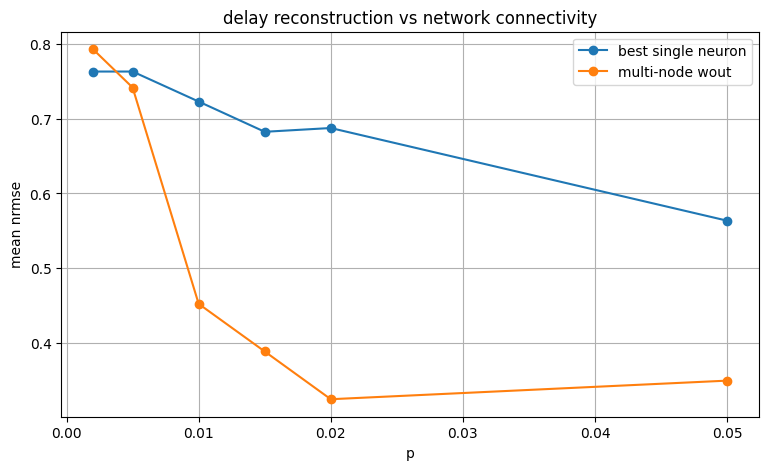

In [21]:
p_vals=[x[0] for x in p_results]
single_vals=[x[1] for x in p_results]
multi_vals=[x[2] for x in p_results]

plt.figure(figsize=(9,5))
plt.plot(p_vals,single_vals,"o-",label="best single neuron")
plt.plot(p_vals,multi_vals,"o-",label="multi-node wout")
plt.xlabel("p")
plt.ylabel("mean nrmse")
plt.title("delay reconstruction vs network connectivity")
plt.legend()
plt.grid()
plt.show()

In [22]:
# check how neuron selection changes with gamma
tau=3.0
gammas=[10,15,20,30]
transition_results=[]

for gamma in gammas:
    k=int(round(tau*gamma))
    N=int(round((tau+1)*gamma))
    width=np.sqrt(k)/gamma

    R=run_chain(data,N,gamma,sigma,win,dt)
    R_train=R[start:train_len]
    R_test=R[train_len:]

    best,nrmses=scan_single_nodes(R_train,y_train,R_test,y_test,beta)
    Wout,Wscaled=train_lasso(R_train,y_train,alpha)

    prediction=R_test@Wout
    multi=np.sqrt(np.mean((prediction-y_test)**2))/np.std(y_test)
    selected=np.where(np.abs(Wscaled)>1e-10)[0]

    transition_results.append([gamma,k,width,len(selected),nrmses[best],multi])

    print("gamma:",gamma)
    print("k:",k)
    print("width:",width)
    print("selected neurons:",selected)
    print("best single nrmse:",nrmses[best])
    print("multi nrmse:",multi)
    print()

    del R,R_train,R_test

gamma: 10
k: 30
width: 0.5477225575051661
selected neurons: [29]
best single nrmse: 0.01669551021121488
multi nrmse: 0.20159241069924938

gamma: 15
k: 45
width: 0.447213595499958
selected neurons: [44]
best single nrmse: 0.012002060355009489
multi nrmse: 0.20163849824167493

gamma: 20
k: 60
width: 0.3872983346207417
selected neurons: [59]
best single nrmse: 0.009478097141515462
multi nrmse: 0.20167680433782995

gamma: 30
k: 90
width: 0.31622776601683794
selected neurons: [89]
best single nrmse: 0.0073222264487196815
multi nrmse: 0.20173612470965363



In [23]:
# compare a narrow and broad delay case
for gamma in [2,30]:
    k=int(round(tau*gamma))
    N=int(round((tau+1)*gamma))
    R=run_chain(data,N,gamma,sigma,win,dt)
    R_train=R[start:train_len]
    R_test=R[train_len:]
    best,nrmses=scan_single_nodes(R_train,y_train,R_test,y_test,beta)
    Wout,Wscaled=train_lasso(R_train,y_train,alpha)
    selected=np.where(np.abs(Wscaled)>1e-10)[0]

    print("gamma:",gamma)
    print("best neuron:",best)
    print("selected neurons:",selected)
    print("selected weights:",np.round(Wscaled[selected],4))
    print()

gamma: 2
best neuron: 5
selected neurons: [5 6]
selected weights: [0.5848 0.2241]

gamma: 30
best neuron: 89
selected neurons: [89]
selected weights: [0.8001]



## One- and two-neuron reconstruction

In [24]:
# compare one and two neurons using the same alpha
gamma=2
alpha_check=0.2

node=int(round(tau*gamma))-1
nodes=[node,node+1]

N=int(round((tau+1)*gamma))

# run the gamma=2 clean chain
R=run_chain(data,N,gamma,sigma,win,dt)

R_train=R[start:train_len]
R_test=R[train_len:]

# train both readouts using alpha=0.2
W1,S1=train_lasso(
    R_train[:,[node]],y_train,alpha_check
)

W2,S2=train_lasso(
    R_train[:,nodes],y_train,alpha_check
)

# derivative of the one-neuron readout
d1=gamma*W1[0]*(
    -R_test[:,node]
    +np.tanh(R_test[:,node-1])
)

# derivative of the two-neuron readout
d2=(
    gamma*W2[0]*(-R_test[:,node]+np.tanh(R_test[:,node-1]))
    +gamma*W2[1]*(-R_test[:,node+1]+np.tanh(R_test[:,node]))
)

# true derivative of h(t-3)
h2tau=data[
    train_len-2*delay_steps:
    len(data)-2*delay_steps,0
]

dtrue=-delta*y_test-np.tanh(kappa*h2tau)

# calculate test derivative errors
error1=np.sqrt(np.mean((d1-dtrue)**2))/np.std(dtrue)
error2=np.sqrt(np.mean((d2-dtrue)**2))/np.std(dtrue)

print("gamma:",gamma)
print("alpha:",alpha_check)
print("one-neuron weight:",W1)
print("two-neuron weights:",W2)
print("one-neuron test derivative nrmse:",error1)
print("two-neuron test derivative nrmse:",error2)

gamma: 2
alpha: 0.2
one-neuron weight: [25.38920598]
two-neuron weights: [18.75064717  7.66988308]
one-neuron test derivative nrmse: 0.2522645863057167
two-neuron test derivative nrmse: 0.21787260265533076


In [25]:
# compare one and two neurons using the same alpha
gamma=2
alpha_check=0.2

node=int(round(tau*gamma))-1
nodes=[node,node+1]

N=int(round((tau+1)*gamma))

# run the clean chain
R=run_chain(data,N,gamma,sigma,win,dt)

R_train=R[start:train_len]
R_test=R[train_len:]

# train both readouts with the same lasso penalty
W1,S1=train_lasso(
    R_train[:,[node]],y_train,alpha_check
)

W2,S2=train_lasso(
    R_train[:,nodes],y_train,alpha_check
)

# calculate the one-neuron derivative
d1=gamma*W1[0]*(
    -R_test[:,node]
    +np.tanh(R_test[:,node-1])
)

# calculate the two-neuron derivative
d2=(
    gamma*W2[0]*(
        -R_test[:,node]
        +np.tanh(R_test[:,node-1])
    )
    +gamma*W2[1]*(
        -R_test[:,node+1]
        +np.tanh(R_test[:,node])
    )
)

# calculate the true delayed gzt derivative
h2tau=data[
    train_len-2*delay_steps:
    len(data)-2*delay_steps,0
]

dtrue=-delta*y_test-np.tanh(kappa*h2tau)

# compare both derivatives on the test data
error1=np.sqrt(
    np.mean((d1-dtrue)**2)
)/np.std(dtrue)

error2=np.sqrt(
    np.mean((d2-dtrue)**2)
)/np.std(dtrue)

print("gamma:",gamma)
print("alpha:",alpha_check)
print("one-neuron weight:",W1)
print("two-neuron weights:",W2)
print("one-neuron test derivative nrmse:",error1)
print("two-neuron test derivative nrmse:",error2)

gamma: 2
alpha: 0.2
one-neuron weight: [25.38920598]
two-neuron weights: [18.75064717  7.66988308]
one-neuron test derivative nrmse: 0.2522645863057167
two-neuron test derivative nrmse: 0.21787260265533076


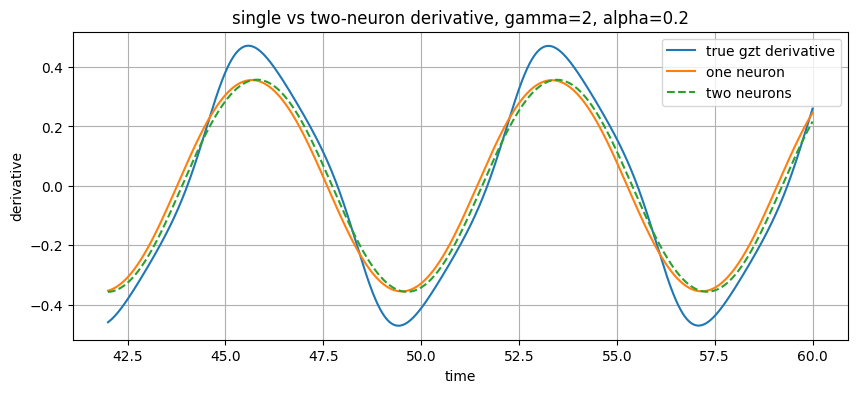

In [26]:
# plot the true and reconstructed derivatives
plt.figure(figsize=(10,4))

plt.plot(
    time[train_len:],
    dtrue,
    label="true gzt derivative"
)

plt.plot(
    time[train_len:],
    d1,
    label="one neuron"
)

plt.plot(
    time[train_len:],
    d2,
    linestyle="--",
    label="two neurons"
)

plt.xlabel("time")
plt.ylabel("derivative")
plt.title("single vs two-neuron derivative, gamma=2, alpha=0.2")

plt.legend()
plt.grid()
plt.show()

In [27]:
# the two output weights from the corrected experiment
w5=W2[0]
w6=W2[1]

# reconstruct h(t-3)
yhat=w5*R_test[:,5]+w6*R_test[:,6]

# calculate the derivative using the reservoir equation
decay=-gamma*yhat
input4=gamma*w5*np.tanh(R_test[:,4])
input5=gamma*w6*np.tanh(R_test[:,5])
dhat=decay+input4+input5

# calculate the true derivative using the gzt equation
h2tau=data[
    train_len-2*delay_steps:
    len(data)-2*delay_steps,0
]

dtrue=-delta*y_test-np.tanh(kappa*h2tau)

# compare both equations at one test time
i=len(y_test)//2

print("time:",time[train_len+i])
print("reconstructed h(t-3):",yhat[i])
print("true h(t-3):",y_test[i])
print("reservoir decay:",decay[i])
print("input from neuron 4:",input4[i])
print("input from neuron 5:",input5[i])
print("reservoir derivative:",dhat[i])
print("true gzt derivative:",dtrue[i])

# compare over the whole test set
error=np.sqrt(np.mean((dhat-dtrue)**2))/np.std(dtrue)

print("derivative nrmse:",error)

time: 51.0
reconstructed h(t-3): -0.39416878394511434
true h(t-3): -0.473404096001563
reservoir decay: 0.7883375678902287
input from neuron 4: -0.7012165726832628
input from neuron 5: -0.24862172745193947
reservoir derivative: -0.16150073224497355
true gzt derivative: -0.198882497874102
derivative nrmse: 0.21787260265533076


In [28]:
# search for a one-to-two switch
gammas=[10,8,6,5,4,3,2,1.5,1]
alphas=[1e-3,3e-3,1e-2]

split=int(0.8*len(y_train))
y_fit=y_train[:split]

previous={a:None for a in alphas}
found=False

for g in gammas:
    # run the clean chain
    N=int(round((tau+1)*g))
    Rg=run_chain(data,N,g,sigma,win,dt)
    R_fit=Rg[start:start+split]

    for a in alphas:
        # train lasso using only fitting data
        Wout,Wscaled=train_lasso(R_fit,y_fit,a)
        selected=np.where(np.abs(Wscaled)>1e-10)[0]
        weights=Wout[selected]

        print("gamma:",g,"alpha:",a)
        print("selected:",selected)
        print("weights:",np.round(weights,4))

        # check for a one-to-two switch
        if previous[a] is not None:
            old_g,old_count=previous[a]

            if old_count==1 and len(selected)==2:
                print("ONE-TO-TWO CANDIDATE:",old_g,"to",g)
                found=True

        # check for two neurons with opposite weights
        if len(selected)==2 and weights[0]*weights[1]<0:
            print("OPPOSITE WEIGHTS FOUND")
            found=True

        previous[a]=(g,len(selected))

if not found:
    print("no candidate found in this sweep")

gamma: 10 alpha: 0.001
selected: [28 29 30 31 32]
weights: [8.7816 6.5702 4.34   2.1956 0.4276]
gamma: 10 alpha: 0.003
selected: [28 29 30 31]
weights: [ 5.6672 10.4213  5.4618  0.6805]
gamma: 10 alpha: 0.01
selected: [28 29 30]
weights: [ 4.0767 12.7241  5.2587]
gamma: 8 alpha: 0.001
selected: [22 23 24 25]
weights: [6.5543 9.5045 5.3588 1.4443]
gamma: 8 alpha: 0.003
selected: [22 23 24]
weights: [ 4.392  12.3543  6.0324]
gamma: 8 alpha: 0.01
selected: [22 23 24]
weights: [ 0.425  20.1182  2.0332]
gamma: 6 alpha: 0.001
selected: [16 17 18]
weights: [ 3.9708 13.3983  6.4402]
gamma: 6 alpha: 0.003
selected: [16 17 18]
weights: [ 3.4625 14.3536  5.9357]
gamma: 6 alpha: 0.01
selected: [17 18]
weights: [21.1402  2.3792]
gamma: 5 alpha: 0.001
selected: [13 14 15]
weights: [ 3.6383 14.1958  6.8025]
gamma: 5 alpha: 0.003
selected: [13 14 15]
weights: [ 0.6294 20.1594  3.7171]
gamma: 5 alpha: 0.01
selected: [14 15]
weights: [21.2944  3.0207]
gamma: 4 alpha: 0.001
selected: [10 11 12]
weights: 

###LASSO objective

$$
\boxed{
\mathcal{L}(w_1,w_2)
=
\frac{1}{2m}\|Y-X_1w_1-X_2w_2\|_2^2
+\alpha(|w_1|+|w_2|)
}
$$


###Zero coefficient optimality condition


$$
e=Y-X_1\hat{w}_1
$$

The second neuron's coefficient can remain zero when:

$$
\boxed{
\frac{|X_2^Te|}{m}\leq\alpha
}
$$

### Whether the second neuron enters the readout

$$
\boxed{
Q=\frac{|X_2^Te|}{m\alpha}
}
$$

$$
\begin{aligned}
Q\leq 1
&\quad\Rightarrow\quad w_2=0
\text{ satisfies the zero-coefficient condition}\\[6pt]
Q>1
&\quad\Rightarrow\quad \text{the second neuron enters the two-neuron LASSO fit}
\end{aligned}
$$

In [29]:
# look for one-to-two lasso selection
gammas=[10,8,6,5,4,3,2]
alphas=[0.02,0.03,0.05,0.1,0.2]

split=int(0.8*len(y_train))
y_fit=y_train[:split]

for g in gammas:
    N=int(round((tau+1)*g))
    Rg=run_chain(data,N,g,sigma,win,dt)
    R_fit=Rg[start:start+split]

    print("\ngamma:",g)

    for a in alphas:
        Wout,Wscaled=train_lasso(R_fit,y_fit,a)
        selected=np.where(np.abs(Wscaled)>1e-10)[0]

        print("alpha:",a,
              "selected:",selected,
              "weights:",np.round(Wout[selected],3))


gamma: 10
alpha: 0.02 selected: [29 30] weights: [20.691  1.118]
alpha: 0.03 selected: [29 30] weights: [20.505  1.081]
alpha: 0.05 selected: [29 30] weights: [20.233  0.906]
alpha: 0.1 selected: [29 30] weights: [19.675  0.348]
alpha: 0.2 selected: [29] weights: [17.798]

gamma: 8
alpha: 0.02 selected: [23 24] weights: [20.778  1.564]
alpha: 0.03 selected: [23 24] weights: [20.645  1.469]
alpha: 0.05 selected: [23 24] weights: [20.414  1.242]
alpha: 0.1 selected: [23 24] weights: [19.838  0.673]
alpha: 0.2 selected: [23] weights: [18.227]

gamma: 6
alpha: 0.02 selected: [17 18] weights: [21.004  2.276]
alpha: 0.03 selected: [17 18] weights: [20.884  2.157]
alpha: 0.05 selected: [17 18] weights: [20.644  1.918]
alpha: 0.1 selected: [17 18] weights: [20.042  1.324]
alpha: 0.2 selected: [17 18] weights: [18.838  0.134]

gamma: 5
alpha: 0.02 selected: [14 15] weights: [21.17   2.897]
alpha: 0.03 selected: [14 15] weights: [21.044  2.775]
alpha: 0.05 selected: [14 15] weights: [20.796  2.

In [30]:
# check when the second neuron enters the readout
alpha_check=0.2

split=int(0.8*len(y_train))
y_fit=y_train[:split]

for g in [8,6,5,2]:

    # expected lct stage and width
    k=int(round(tau*g))
    node=k-1
    width=np.sqrt(k)/g

    # run the clean chain
    N=int(round((tau+1)*g))
    Rg=run_chain(data,N,g,sigma,win,dt)

    R_fit=Rg[start:start+split]

    # train the expected neuron alone
    W1,S1=train_lasso(
        R_fit[:,[node]],y_fit,alpha_check
    )

    # train the expected neuron and its neighbour
    W2,S2=train_lasso(
        R_fit[:,[node,node+1]],y_fit,alpha_check
    )

    # use the same scaling as train_lasso
    x1=R_fit[:,node]/np.std(R_fit[:,node])
    x2=R_fit[:,node+1]/np.std(R_fit[:,node+1])

    # residual left by the one-neuron readout
    residual=y_fit/np.std(y_fit)-S1[0]*x1

    # lasso selection condition for the second neuron
    Q=np.abs(x2@residual)/(len(y_fit)*alpha_check)

    # check the fitted second-neuron coefficient
    second_selected=np.abs(S2[1])>1e-10

    print(
        "gamma:",g,
        "| width:",round(width,4),
        "| Q:",round(Q,6),
        "| second weight:",round(W2[1],4),
        "| selected:",second_selected
    )

gamma: 8 | width: 0.6124 | Q: 0.998452 | second weight: 0.0 | selected: False
gamma: 6 | width: 0.7071 | Q: 1.000177 | second weight: 0.0017 | selected: True
gamma: 5 | width: 0.7746 | Q: 1.003497 | second weight: 0.5462 | selected: True
gamma: 2 | width: 1.2247 | Q: 1.170455 | second weight: 7.5477 | selected: True


In [31]:
# check if tanh is approximately linear in the gzt equation
h2tau=data[train_len-2*delay_steps:len(data)-2*delay_steps,0]
x=kappa*h2tau

exact=np.tanh(x)
approx=x

# measure the approximation error
error=np.abs(exact-approx)

print("maximum tanh input:",np.max(np.abs(x)))
print("maximum tanh error:",np.max(error))

# compare the original and simplified gzt derivatives
dtrue=-delta*y_test-exact
dlinear=-delta*y_test-approx

deriv_error=np.sqrt(np.mean((dlinear-dtrue)**2))/np.std(dtrue)
print("linear gzt derivative nrmse:",deriv_error)

maximum tanh input: 0.8217360980903213
maximum tanh error: 0.1457224057207973
linear gzt derivative nrmse: 0.2786124820214062


In [32]:
# compare one and two neurons on the test data
alpha_check=0.2

# true gzt derivative for the test period
h2_test=data[
    train_len-2*delay_steps:
    len(data)-2*delay_steps,0
]

dtrue_test=-delta*y_test-np.tanh(kappa*h2_test)

for g in [8,5,2]:

    k=int(round(tau*g))
    node=k-1
    nodes=[node,node+1]

    N=int(round((tau+1)*g))

    # run the clean chain
    Rg=run_chain(data,N,g,sigma,win,dt)

    R_train=Rg[start:train_len]
    R_test=Rg[train_len:]

    # train both readouts using alpha=0.2
    W1,S1=train_lasso(
        R_train[:,[node]],y_train,alpha_check
    )

    W2,S2=train_lasso(
        R_train[:,nodes],y_train,alpha_check
    )

    # predict h(t-3)
    pred1=W1[0]*R_test[:,node]

    pred2=(
        W2[0]*R_test[:,node]
        +W2[1]*R_test[:,node+1]
    )

    # calculate the one-neuron derivative
    d1=g*W1[0]*(
        -R_test[:,node]
        +np.tanh(R_test[:,node-1])
    )

    # calculate the two-neuron derivative
    d2=(
        g*W2[0]*(-R_test[:,node]+np.tanh(R_test[:,node-1]))
        +g*W2[1]*(-R_test[:,node+1]+np.tanh(R_test[:,node]))
    )

    # signal test errors
    signal_rmse1=np.sqrt(np.mean((pred1-y_test)**2))
    signal_rmse2=np.sqrt(np.mean((pred2-y_test)**2))

    signal_nrmse1=signal_rmse1/np.std(y_test)
    signal_nrmse2=signal_rmse2/np.std(y_test)

    # derivative test errors
    deriv_rmse1=np.sqrt(np.mean((d1-dtrue_test)**2))
    deriv_rmse2=np.sqrt(np.mean((d2-dtrue_test)**2))

    deriv_nrmse1=deriv_rmse1/np.std(dtrue_test)
    deriv_nrmse2=deriv_rmse2/np.std(dtrue_test)

    print("\ngamma:",g)
    print("lct width:",np.sqrt(tau/g))
    print("one-neuron weight:",W1[0])
    print("two-neuron weights:",W2)
    print("one-neuron derivative test NRMSE:",deriv_nrmse1)
    print("two-neuron derivative test NRMSE:",deriv_nrmse2)


gamma: 8
lct width: 0.6123724356957945
one-neuron weight: 18.232481810893226
two-neuron weights: [18.23248181  0.        ]
one-neuron derivative test NRMSE: 0.2055287835358506
two-neuron derivative test NRMSE: 0.2055287835358506

gamma: 5
lct width: 0.7745966692414834
one-neuron weight: 19.597135568862253
two-neuron weights: [18.93715813  0.6760873 ]
one-neuron derivative test NRMSE: 0.21001484064206413
two-neuron derivative test NRMSE: 0.20938227955922403

gamma: 2
lct width: 1.224744871391589
one-neuron weight: 25.389205980568406
two-neuron weights: [18.75064717  7.66988308]
one-neuron derivative test NRMSE: 0.2522645863057167
two-neuron derivative test NRMSE: 0.21787260265533076


In [33]:
# compare the actual terms at one test time
gamma=2
alpha_check=0.2
w_previous=1.0

n=int(round(tau*gamma))-1
N=int(round((tau+1)*gamma))

# run the clean chain and fit one neuron
R_compare=run_chain(data,N,gamma,sigma,win,dt)

R_train_compare=R_compare[start:train_len]
R_test_compare=R_compare[train_len:]

W1,S1=train_lasso(
    R_train_compare[:,[n]],y_train,alpha_check
)

wout=W1[0]

# choose the middle of the test period
i=len(y_test)//2

rn=R_test_compare[i,n]
r_previous=R_test_compare[i,n-1]

h_tau=y_test[i]
h_2tau=data[train_len+i-2*delay_steps,0]

# reservoir terms
reservoir_decay=-gamma*wout*rn
reservoir_input=gamma*wout*np.tanh(w_previous*r_previous)
reservoir_derivative=reservoir_decay+reservoir_input

# gzt terms for the delayed target h(t-3)
gzt_decay=-delta*h_tau
gzt_feedback=-np.tanh(kappa*h_2tau)
gzt_derivative=gzt_decay+gzt_feedback

print("time:",time[train_len+i])
print("gamma:",gamma,"delta:",delta,"kappa:",kappa)
print("-gamma:",-gamma,"-delta:",-delta)
print("connection weight:",w_previous)
print("output weight:",wout)

print("\nSTATE COMPARISON")
print("r_n:",rn)
print("wout * r_n:",wout*rn)
print("h(t-3):",h_tau)
print("r_(n-1):",r_previous)
print("h(t-3) - r_(n-1):",h_tau-r_previous)

print("\nTANH COMPARISON YOU ASKED FOR")
print("tanh(w_previous * r_previous):",
      np.tanh(w_previous*r_previous))
print("tanh(kappa * h(t-3)):",
      np.tanh(kappa*h_tau))

print("\nDECAY TERMS")
print("reservoir -gamma * wout * r_n:",reservoir_decay)
print("gzt -delta * h(t-3):",gzt_decay)
print("difference:",reservoir_decay-gzt_decay)

print("\nINPUT AND FEEDBACK TERMS")
print("reservoir gamma * wout * tanh(r_previous):",
      reservoir_input)
print("gzt -tanh(kappa * h(t-6)):",gzt_feedback)
print("difference:",reservoir_input-gzt_feedback)

print("\nTOTAL DERIVATIVES")
print("reservoir:",reservoir_derivative)
print("gzt:",gzt_derivative)
print("difference:",reservoir_derivative-gzt_derivative)

time: 51.0
gamma: 2 delta: 1.0 kappa: 1.5
-gamma: -2 -delta: -1.0
connection weight: 1.0
output weight: 25.389205980568406

STATE COMPARISON
r_n: -0.016209080271708427
wout * r_n: -0.411535677773973
h(t-3): -0.473404096001563
r_(n-1): -0.01870064286654141
h(t-3) - r_(n-1): -0.4547034531350216

TANH COMPARISON YOU ASKED FOR
tanh(w_previous * r_previous): -0.018698463212298122
tanh(kappa * h(t-3)): -0.6107433886259872

DECAY TERMS
reservoir -gamma * wout * r_n: 0.823071355547946
gzt -delta * h(t-3): 0.473404096001563
difference: 0.34966725954638295

INPUT AND FEEDBACK TERMS
reservoir gamma * wout * tanh(r_previous): -0.9494782680342356
gzt -tanh(kappa * h(t-6)): -0.672286593875665
difference: -0.2771916741585706

TOTAL DERIVATIVES
reservoir: -0.12640691248628966
gzt: -0.198882497874102
difference: 0.07247558538781235


In [34]:
# compare individual derivative terms
gamma=2
alpha_check=0.2

node=int(round(tau*gamma))-1
nodes=[node,node+1]

N=int(round((tau+1)*gamma))

# run clean chain
R=run_chain(data,N,gamma,sigma,win,dt)

R_train=R[start:train_len]
R_test=R[train_len:]

# one-neuron readout
W1,S1=train_lasso(
    R_train[:,[node]],
    y_train,
    alpha_check
)

# two-neuron readout
W2,S2=train_lasso(
    R_train[:,nodes],
    y_train,
    alpha_check
)

# reconstructed h(t)
hhat1=W1[0]*R_test[:,node]

hhat2=(
    W2[0]*R_test[:,node]
    +W2[1]*R_test[:,node+1]
)

decay1=-gamma*hhat1
decay2=-gamma*hhat2

gzt_decay=-delta*y_test

incoming1=(
    gamma*W1[0]
    *np.tanh(R_test[:,node-1])
)

incoming2=(
    gamma*W2[0]
    *np.tanh(R_test[:,node-1])
    +
    gamma*W2[1]
    *np.tanh(R_test[:,node])
)

h_previous=data[
    train_len-2*delay_steps:
    len(data)-2*delay_steps,0
]

gzt_feedback=-np.tanh(kappa*h_previous)
decay_diff1=np.mean(np.abs(decay1-gzt_decay))
decay_diff2=np.mean(np.abs(decay2-gzt_decay))

feedback_diff1=np.mean(np.abs(incoming1-gzt_feedback))
feedback_diff2=np.mean(np.abs(incoming2-gzt_feedback))

print("gamma:",gamma)
print("one-neuron weight:",W1[0])
print("two-neuron weights:",W2)

print("\nMEAN ABSOLUTE DIFFERENCE")

print("decay:")
print("one neuron:",decay_diff1)
print("two neurons:",decay_diff2)

print("\nfeedback / incoming:")
print("one neuron:",feedback_diff1)
print("two neurons:",feedback_diff2)

gamma: 2
one-neuron weight: 25.389205980568406
two-neuron weights: [18.75064717  7.66988308]

MEAN ABSOLUTE DIFFERENCE
decay:
one neuron: 0.2196497298002478
two neurons: 0.21260912891667152

feedback / incoming:
one neuron: 0.18467006657382404
two neurons: 0.21804355945714265


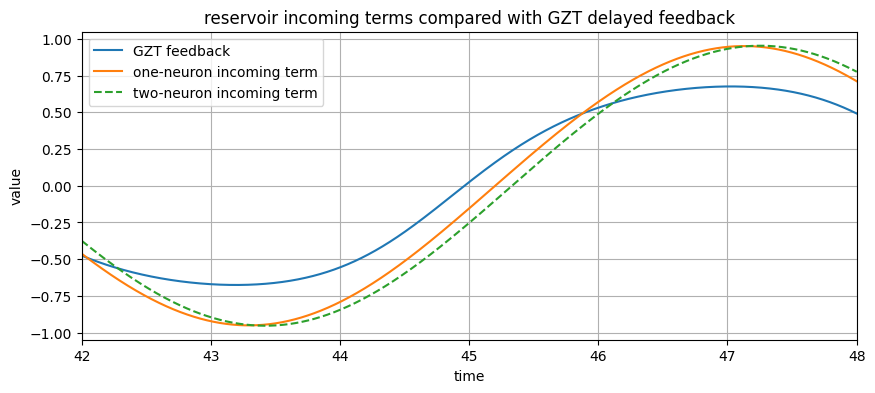

In [35]:
# compare reservoir incoming terms with GZT feedback

plt.figure(figsize=(10,4))

plt.plot(
    time[train_len:],
    gzt_feedback,
    label="GZT feedback"
)

plt.plot(
    time[train_len:],
    incoming1,
    label="one-neuron incoming term"
)

plt.plot(
    time[train_len:],
    incoming2,
    label="two-neuron incoming term",
    linestyle="--"
)

plt.xlim(time[train_len],time[train_len]+6)

plt.xlabel("time")
plt.ylabel("value")
plt.title("reservoir incoming terms compared with GZT delayed feedback")
plt.legend()
plt.grid()
plt.show()

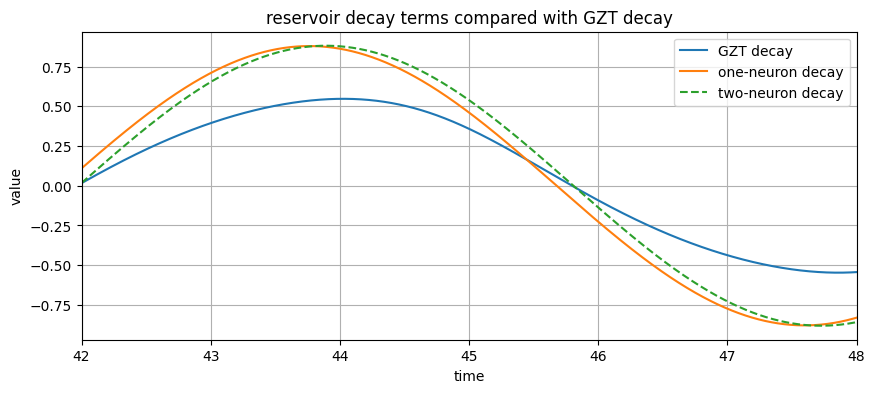

In [36]:
# compare decay terms

plt.figure(figsize=(10,4))

plt.plot(
    time[train_len:],
    gzt_decay,
    label="GZT decay"
)

plt.plot(
    time[train_len:],
    decay1,
    label="one-neuron decay"
)

plt.plot(
    time[train_len:],
    decay2,
    label="two-neuron decay",
    linestyle="--"
)

plt.xlim(time[train_len],time[train_len]+6)

plt.xlabel("time")
plt.ylabel("value")
plt.title("reservoir decay terms compared with GZT decay")
plt.legend()
plt.grid()
plt.show()

In [37]:
# compare term differences over the whole test period

gamma=2
alpha_check=0.2

# selected neuron from lct
n=int(round(tau*gamma))-1
N=int(round((tau+1)*gamma))

# run reservoir
R=run_chain(data,N,gamma,sigma,win,dt)

R_train=R[start:train_len]
R_test=R[train_len:]

# train one-neuron readout
W_one,S_one=train_lasso(
    R_train[:,[n]],
    y_train,
    alpha_check
)

wout=W_one[0]

print("gamma:",gamma)
print("neuron:",n)
print("output weight:",wout)

# reservoir terms
reservoir_decay=-gamma*wout*R_test[:,n]

reservoir_feedback=gamma*wout*np.tanh(
    R_test[:,n-1]
)

reservoir_total=reservoir_decay+reservoir_feedback

# gzt terms
h_tau=y_test

h_2tau=data[
    train_len-2*delay_steps:
    len(data)-2*delay_steps,0
]

gzt_decay=-delta*h_tau

gzt_feedback=-np.tanh(kappa*h_2tau)

gzt_total=gzt_decay+gzt_feedback

# differences
decay_difference=reservoir_decay-gzt_decay

feedback_difference=reservoir_feedback-gzt_feedback

total_difference=reservoir_total-gzt_total

# check that total difference is the sum of the two term differences
same_check=decay_difference+feedback_difference

# error measures
rmse=np.sqrt(np.mean(total_difference**2))
nrmse=rmse/np.std(gzt_total)

print("\nmean absolute decay difference:",
      np.mean(np.abs(decay_difference)))

print("mean absolute feedback difference:",
      np.mean(np.abs(feedback_difference)))

print("mean absolute total derivative difference:",
      np.mean(np.abs(total_difference)))

print("\nmean decay difference:",
      np.mean(decay_difference))

print("mean feedback difference:",
      np.mean(feedback_difference))

print("mean total difference:",
      np.mean(total_difference))

print("\nderivative rmse:",rmse)

print("derivative nrmse:",nrmse)

print("opposite signs percentage:",
      100*np.mean(decay_difference*feedback_difference < 0))

gamma: 2
neuron: 5
output weight: 25.389205980568406

mean absolute decay difference: 0.2196497298002478
mean absolute feedback difference: 0.18467006657382404
mean absolute total derivative difference: 0.07417953314437435

mean decay difference: 0.040073306699557575
mean feedback difference: -0.029973540376983666
mean total difference: 0.010099766322573917

derivative rmse: 0.07862072433431712
derivative nrmse: 0.2522645863057167
opposite signs percentage: 90.22777777777777


In [38]:
opposite=np.mean(decay_difference*feedback_difference < 0)

print("fraction with opposite signs:",opposite)
print("percentage:",100*opposite)

fraction with opposite signs: 0.9022777777777777
percentage: 90.22777777777777


In [39]:
# comparing the one-neuron derivative terms for different gamma values

alpha_check=0.2

# true GZT terms over the test period
h_2tau=data[
    train_len-2*delay_steps:
    len(data)-2*delay_steps,0
]

gzt_decay=-delta*y_test
gzt_feedback=-np.tanh(kappa*h_2tau)

for g in [2,5,8]:

    # expected neuron for tau=3
    k=int(round(tau*g))
    node=k-1

    N=int(round((tau+1)*g))

    # clean chain
    Rg=run_chain(data,N,g,sigma,win,dt)

    R_train=Rg[start:train_len]
    R_test=Rg[train_len:]

    # one-neuron readout
    W1,S1=train_lasso(
        R_train[:,[node]],
        y_train,
        alpha_check
    )

    w=W1[0]

    # reconstructed signal
    hhat=w*R_test[:,node]

    # reservoir derivative terms
    reservoir_decay=-g*hhat

    reservoir_feedback=(
        g*w*np.tanh(R_test[:,node-1])
    )

    # differences from GZT terms
    decay_difference=reservoir_decay-gzt_decay
    feedback_difference=reservoir_feedback-gzt_feedback

    total_difference=decay_difference+feedback_difference

    # how often do the two differences oppose each other?
    opposite=np.mean(
        decay_difference*feedback_difference < 0
    )

    print("\ngamma:",g)
    print("neuron:",node)
    print("output weight:",w)

    print("mean absolute decay difference:",
          np.mean(np.abs(decay_difference)))

    print("mean absolute feedback difference:",
          np.mean(np.abs(feedback_difference)))

    print("mean absolute total derivative difference:",
          np.mean(np.abs(total_difference)))

    print("mean decay difference:",
          np.mean(decay_difference))

    print("mean feedback difference:",
          np.mean(feedback_difference))

    print("opposite signs percentage:",
          100*opposite)


gamma: 2
neuron: 5
output weight: 25.389205980568406
mean absolute decay difference: 0.2196497298002478
mean absolute feedback difference: 0.18467006657382404
mean absolute total derivative difference: 0.07417953314437435
mean decay difference: 0.040073306699557575
mean feedback difference: -0.029973540376983666
opposite signs percentage: 90.22777777777777

gamma: 5
neuron: 14
output weight: 19.597135568862253
mean absolute decay difference: 1.074940810623604
mean absolute feedback difference: 1.070708119649112
mean absolute total derivative difference: 0.05735282103080095
mean decay difference: 0.17962559242223916
mean feedback difference: -0.17376578126203934
opposite signs percentage: 98.19444444444444

gamma: 8
neuron: 23
output weight: 18.232481810893226
mean absolute decay difference: 1.9336492036769284
mean absolute feedback difference: 1.9314072193240528
mean absolute total derivative difference: 0.05570565050780342
mean decay difference: 0.32034485748255226
mean feedback diff

In [44]:
gamma = 2
alpha_check = 0.2

# LCT predicted neuron
n = int(round(tau * gamma)) - 1
N = int(round((tau + 1) * gamma))

# run the clean chain
R_one = run_chain(data, N, gamma, sigma, win, dt)

R_train_one = R_one[start:train_len]
R_test_one = R_one[train_len:]

# train the one-neuron readout
W_one, S_one = train_lasso(
    R_train_one[:, [n]],
    y_train,
    alpha_check
)

wout = W_one[0]

# selected neuron and previous neuron
r_n = R_test_one[:, n]
r_prev = R_test_one[:, n - 1]

# time axis written in terms of the delayed target
t_plot = time[train_len:] - tau

# h(t-tau) when t is the target time
h_previous = data[
    train_len - 2 * delay_steps:
    len(data) - 2 * delay_steps,
    0
]

print("neuron:", n)
print("previous neuron:", n - 1)
print("output weight:", wout)

neuron: 5
previous neuron: 4
output weight: 25.389205980568406


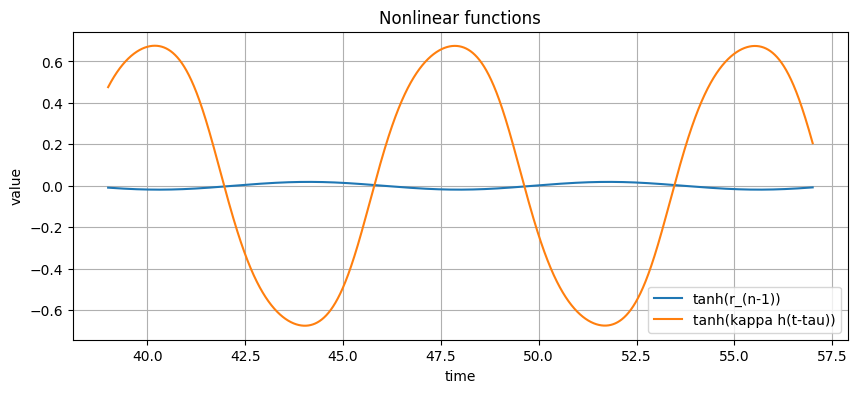

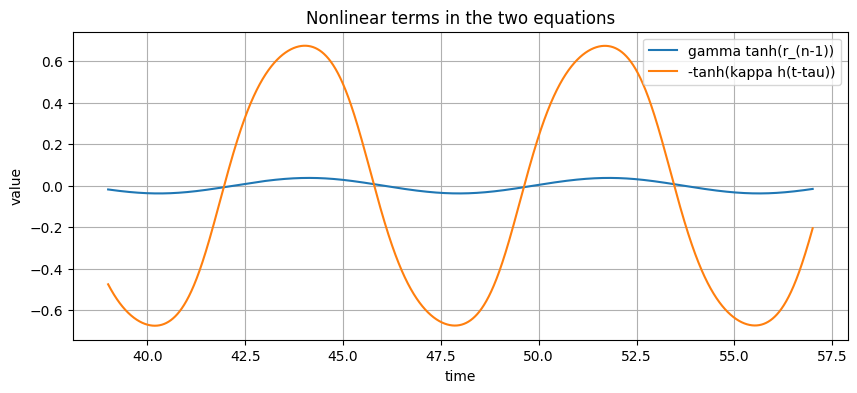

In [45]:
plt.figure(figsize=(10,4))
plt.plot(t_plot,np.tanh(r_prev),label="tanh(r_(n-1))")
plt.plot(t_plot,np.tanh(kappa*h_previous),label="tanh(kappa h(t-tau))")
plt.xlabel("time")
plt.ylabel("value")
plt.title("Nonlinear functions")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(10,4))
plt.plot(t_plot,gamma*np.tanh(r_prev),label="gamma tanh(r_(n-1))")
plt.plot(t_plot,-np.tanh(kappa*h_previous),label="-tanh(kappa h(t-tau))")
plt.xlabel("time")
plt.ylabel("value")
plt.title("Nonlinear terms in the two equations")
plt.legend()
plt.grid()
plt.show()

r5 expected mean delay: 3.0
r4 expected mean delay: 2.5
correlation r5 with h(s-3): 0.9922075108577905
correlation r4 with h(s-2.5): 0.9943630623197462


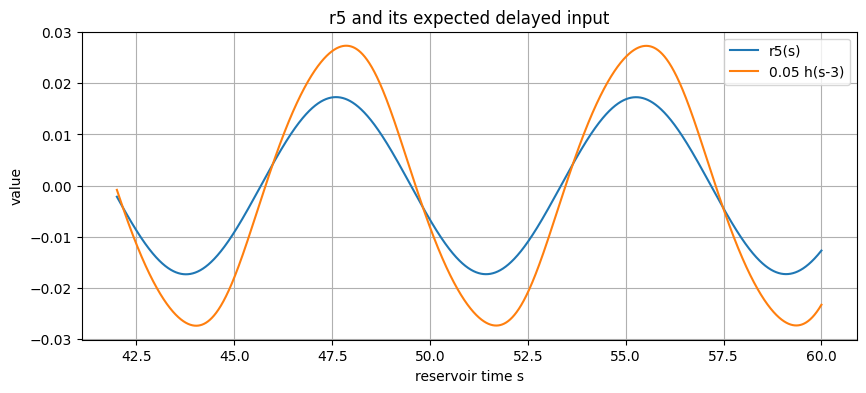

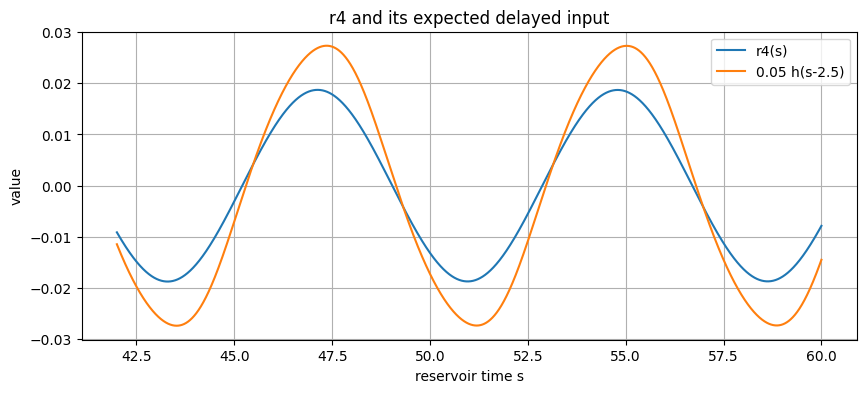

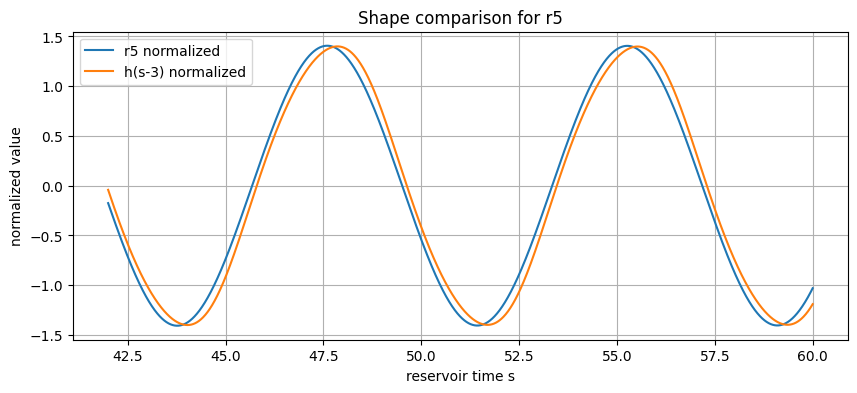

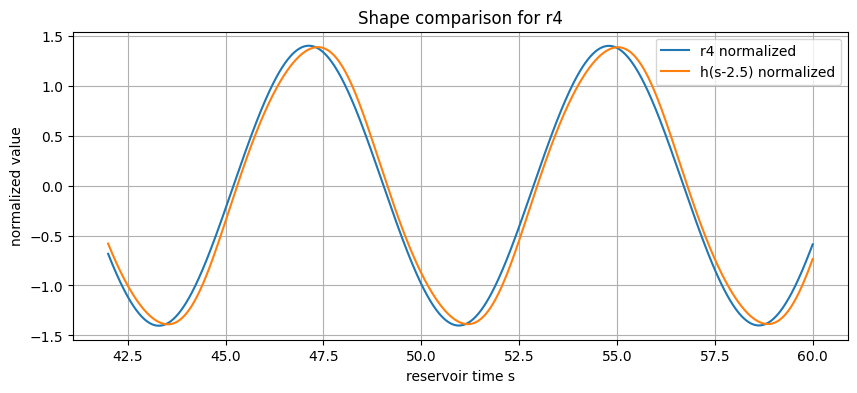

In [46]:
# check what r5 and r4 represent

gamma=2
n=5

# reservoir states on test set
r5=R_test_one[:,5]
r4=R_test_one[:,4]

# effective input scaling
input_scale=sigma*win

# delays predicted from chain position
delay_r5=(5+1)/gamma      # stage 6
delay_r4=(4+1)/gamma      # stage 5

steps_r5=int(round(delay_r5/dt))
steps_r4=int(round(delay_r4/dt))

# h values at the corresponding delays
h_r5=data[train_len-steps_r5:len(data)-steps_r5,0]
h_r4=data[train_len-steps_r4:len(data)-steps_r4,0]

print("r5 expected mean delay:",delay_r5)
print("r4 expected mean delay:",delay_r4)

print("correlation r5 with h(s-3):",
      np.corrcoef(r5,h_r5)[0,1])

print("correlation r4 with h(s-2.5):",
      np.corrcoef(r4,h_r4)[0,1])


# r5 compared with delayed input
plt.figure(figsize=(10,4))
plt.plot(time[train_len:],r5,label="r5(s)")
plt.plot(time[train_len:],input_scale*h_r5,label="0.05 h(s-3)")
plt.xlabel("reservoir time s")
plt.ylabel("value")
plt.title("r5 and its expected delayed input")
plt.legend()
plt.grid()
plt.show()


# r4 compared with delayed input
plt.figure(figsize=(10,4))
plt.plot(time[train_len:],r4,label="r4(s)")
plt.plot(time[train_len:],input_scale*h_r4,label="0.05 h(s-2.5)")
plt.xlabel("reservoir time s")
plt.ylabel("value")
plt.title("r4 and its expected delayed input")
plt.legend()
plt.grid()
plt.show()


# normalize to compare shapes without amplitude
r5_norm=r5/np.std(r5)
h5_norm=h_r5/np.std(h_r5)

r4_norm=r4/np.std(r4)
h4_norm=h_r4/np.std(h_r4)

plt.figure(figsize=(10,4))
plt.plot(time[train_len:],r5_norm,label="r5 normalized")
plt.plot(time[train_len:],h5_norm,label="h(s-3) normalized")
plt.xlabel("reservoir time s")
plt.ylabel("normalized value")
plt.title("Shape comparison for r5")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(10,4))
plt.plot(time[train_len:],r4_norm,label="r4 normalized")
plt.plot(time[train_len:],h4_norm,label="h(s-2.5) normalized")
plt.xlabel("reservoir time s")
plt.ylabel("normalized value")
plt.title("Shape comparison for r4")
plt.legend()
plt.grid()
plt.show()

In [50]:
# linear terms
res_linear=-gamma*r5
# delayed DDE states over the test period
h_delay3 = y_test

h_delay6 = data[
    train_len - 2 * delay_steps:
    len(data) - 2 * delay_steps,
    0
]
gzt_linear=-delta*h_delay3

# nonlinear terms
res_nonlinear=gamma*np.tanh(r4)
gzt_nonlinear=-np.tanh(kappa*h_delay6)

# whole derivatives
dr5=res_linear+res_nonlinear
dh=gzt_linear+gzt_nonlinear

# correlations
print("CORRELATIONS")
print("linear:",np.corrcoef(res_linear,gzt_linear)[0,1])
print("nonlinear:",np.corrcoef(res_nonlinear,gzt_nonlinear)[0,1])
print("whole derivative:",np.corrcoef(dr5,dh)[0,1])

# best constant scaling for each comparison
scale_linear=np.dot(res_linear,gzt_linear)/np.dot(res_linear,res_linear)
scale_nonlinear=np.dot(res_nonlinear,gzt_nonlinear)/np.dot(res_nonlinear,res_nonlinear)
scale_whole=np.dot(dr5,dh)/np.dot(dr5,dr5)

print("\nBEST SCALE FACTORS")
print("linear scale:",scale_linear)
print("nonlinear scale:",scale_nonlinear)
print("whole derivative scale:",scale_whole)
print("trained output weight:",w)

CORRELATIONS
linear: 0.9922075108577901
nonlinear: 0.9851176209644299
whole derivative: 0.9868498483825986

BEST SCALE FACTORS
linear scale: 6.29622223420876
nonlinear scale: 7.505047116040813
whole derivative scale: 12.608084311154736
trained output weight: 19.597135568862253




GAMMA = 2
neuron n = 5
previous neuron = 4
LCT delay r_n = 3.0
LCT delay r_(n-1) = 2.5
output weight = 25.389205980568406

RAW TERM CORRELATIONS
linear correlation: 0.9922075108577905
nonlinear correlation: 0.9851176209644292
raw derivative correlation: 0.9868498483825981

TRAINED OUTPUT ERRORS
mean abs linear error: 0.2196497298002478
mean abs nonlinear error: 0.18467006657382404
mean abs derivative error: 0.07417953314437435
derivative NRMSE: 0.2522645863057167
opposite-sign term errors (%): 90.22777777777777


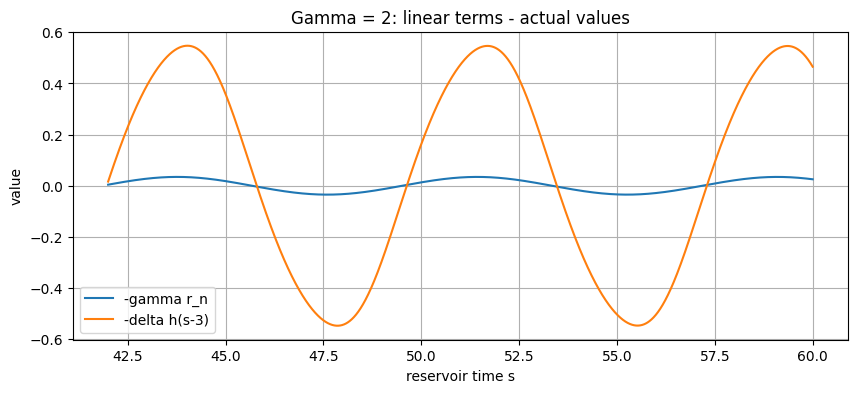

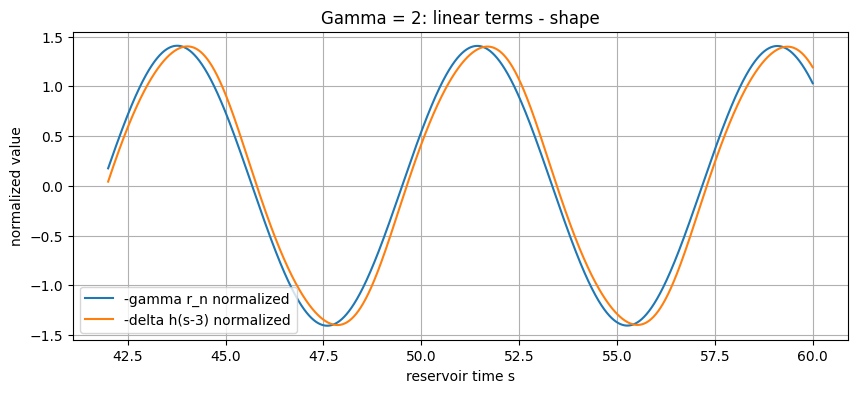

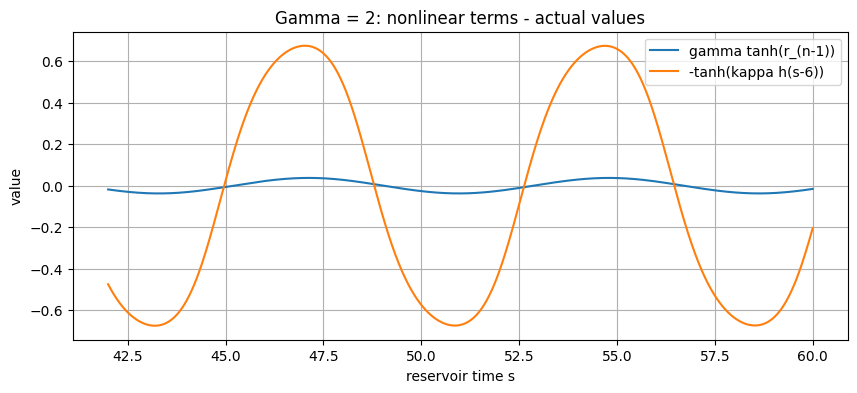

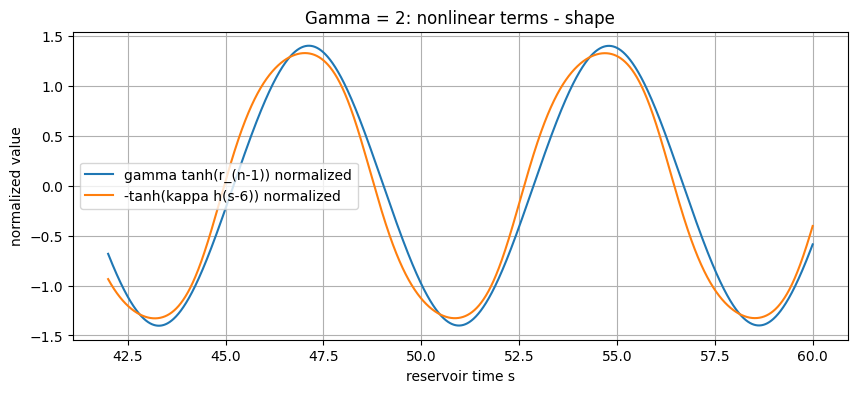

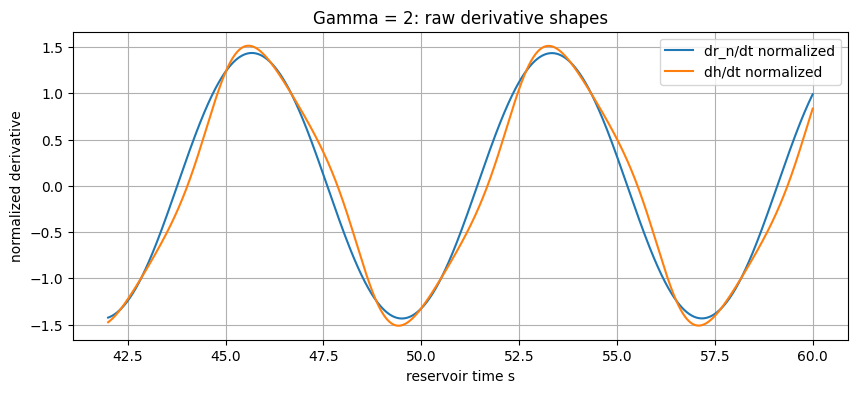

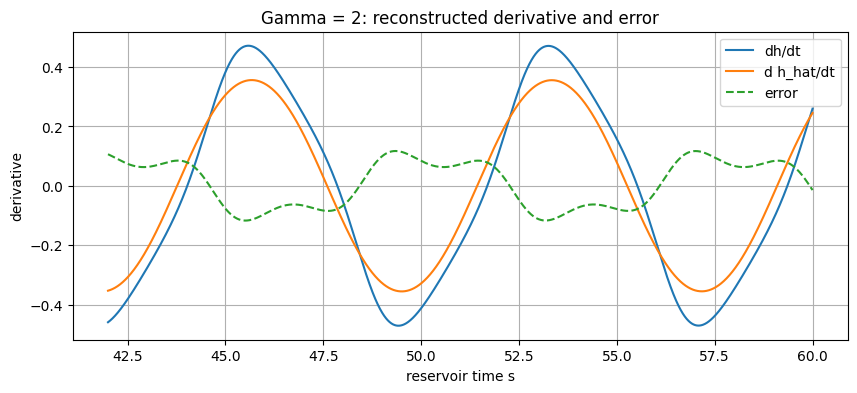

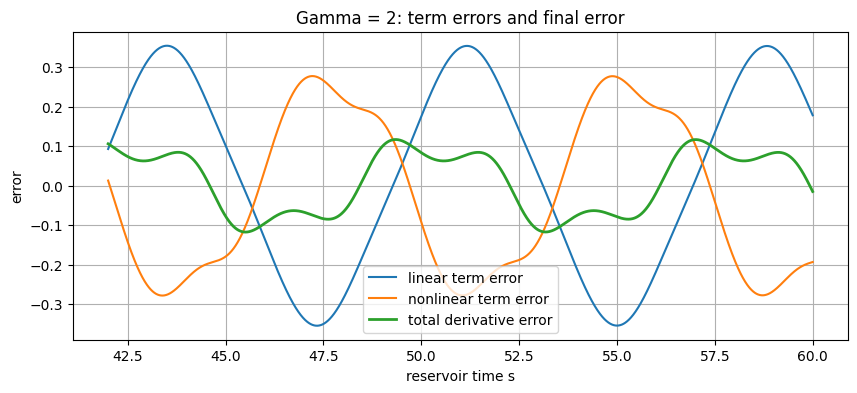



GAMMA = 5
neuron n = 14
previous neuron = 13
LCT delay r_n = 3.0
LCT delay r_(n-1) = 2.8
output weight = 19.597135568862253

RAW TERM CORRELATIONS
linear correlation: 0.9995153337407502
nonlinear correlation: 0.886126003568576
raw derivative correlation: 0.9971055565774511

TRAINED OUTPUT ERRORS
mean abs linear error: 1.0749408106236038
mean abs nonlinear error: 1.070708119649112
mean abs derivative error: 0.057352821030800985
derivative NRMSE: 0.21001484064206416
opposite-sign term errors (%): 98.19444444444444


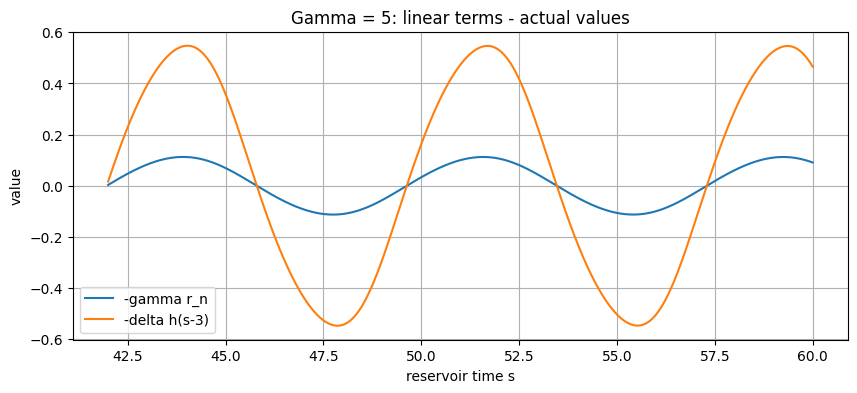

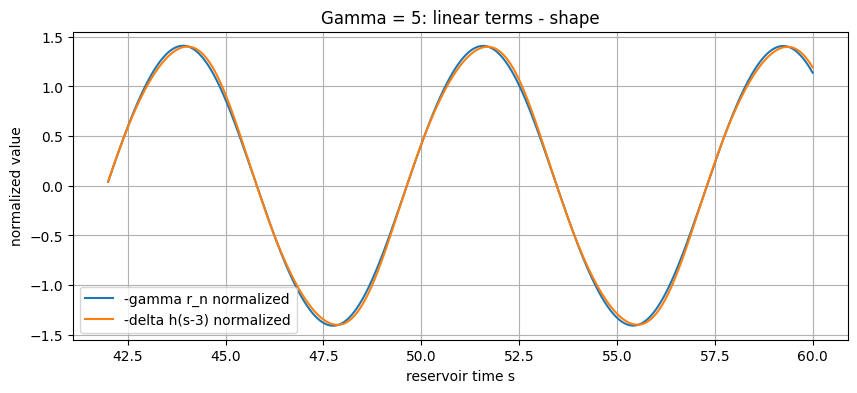

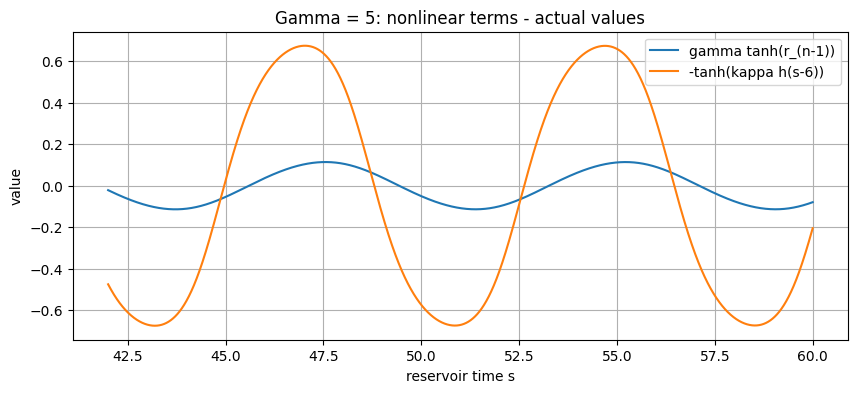

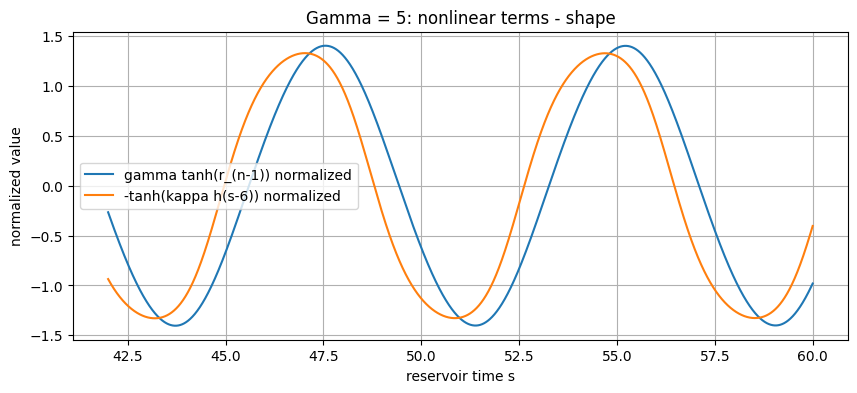

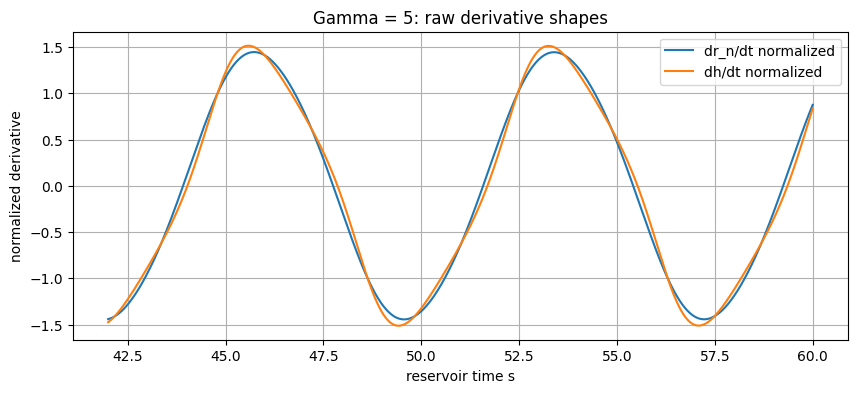

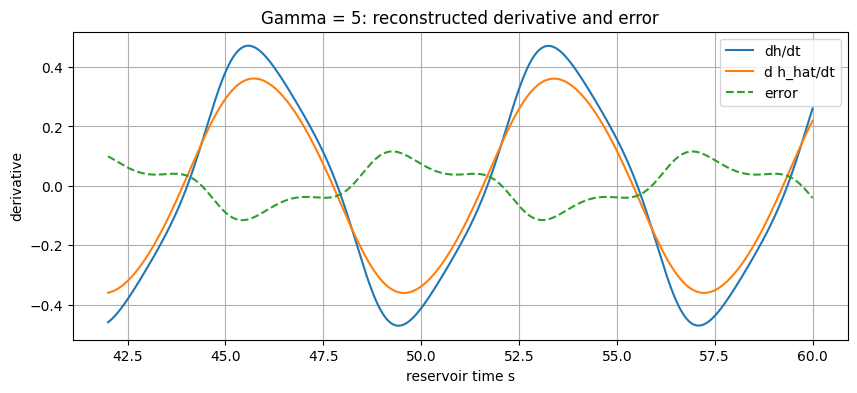

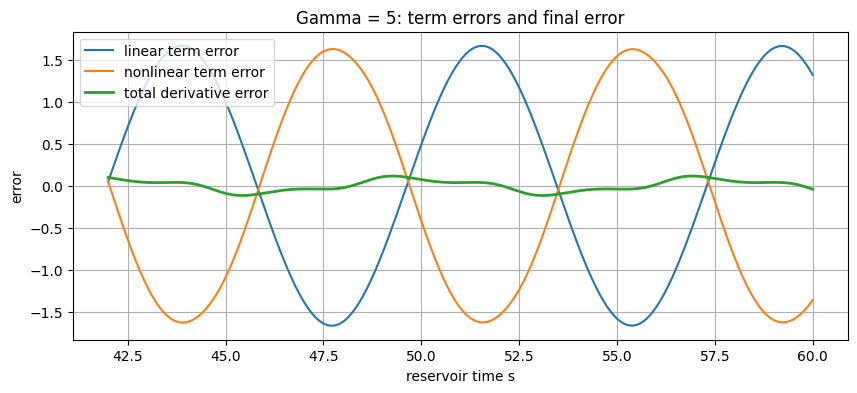

In [51]:
# COMPLETE ONE-NEURON COMPARISON FOR GAMMA = 2 AND 5

gammas=[2,5]
alpha_check=0.2

idx=np.arange(train_len,len(data))
t_s=time[train_len:]

# GZT values are the same for both gamma values
h_s3=data[idx-delay_steps,0]
h_s6=data[idx-2*delay_steps,0]

gzt_linear=-delta*h_s3
gzt_nonlinear=-np.tanh(kappa*h_s6)
dh=gzt_linear+gzt_nonlinear

def normalise(x):
    return x/np.std(x)

def nrmse(true,pred):
    return np.sqrt(np.mean((true-pred)**2))/np.std(true)


for gamma in gammas:

    print("\n")
    print("GAMMA =",gamma)

    # LCT selected neuron
    n=int(round(tau*gamma))-1
    N=int(round((tau+1)*gamma))

    # run clean chain
    R=run_chain(data,N,gamma,sigma,win,dt)

    R_train=R[start:train_len]
    R_test=R[train_len:]

    # train the single neuron
    W_one,S_one=train_lasso(
        R_train[:,[n]],
        y_train,
        alpha_check
    )

    w=W_one[0]

    r_n=R_test[:,n]
    r_prev=R_test[:,n-1]

    # RAW RESERVOIR TERMS

    res_linear=-gamma*r_n
    res_nonlinear=gamma*np.tanh(r_prev)

    dr_n=res_linear+res_nonlinear

    # TRAINED OUTPUT DERIVATIVE
    # h_hat = w*r_n

    h_hat=w*r_n

    scaled_linear=w*res_linear
    scaled_nonlinear=w*res_nonlinear

    d_hhat=scaled_linear+scaled_nonlinear

    # ERRORS
    linear_error=scaled_linear-gzt_linear
    nonlinear_error=scaled_nonlinear-gzt_nonlinear
    derivative_error=d_hhat-dh

    print("neuron n =",n)
    print("previous neuron =",n-1)
    print("LCT delay r_n =", (n+1)/gamma)
    print("LCT delay r_(n-1) =", n/gamma)
    print("output weight =",w)

    print("\nRAW TERM CORRELATIONS")
    print("linear correlation:",
          np.corrcoef(res_linear,gzt_linear)[0,1])
    print("nonlinear correlation:",
          np.corrcoef(res_nonlinear,gzt_nonlinear)[0,1])
    print("raw derivative correlation:",
          np.corrcoef(dr_n,dh)[0,1])

    print("\nTRAINED OUTPUT ERRORS")
    print("mean abs linear error:",
          np.mean(np.abs(linear_error)))
    print("mean abs nonlinear error:",
          np.mean(np.abs(nonlinear_error)))
    print("mean abs derivative error:",
          np.mean(np.abs(derivative_error)))

    print("derivative NRMSE:",
          nrmse(dh,d_hhat))

    print("opposite-sign term errors (%):",
          100*np.mean(linear_error*nonlinear_error < 0))

    # PLOT 1: ACTUAL LINEAR TERMS
    plt.figure(figsize=(10,4))
    plt.plot(t_s,res_linear,label="-gamma r_n")
    plt.plot(t_s,gzt_linear,label="-delta h(s-3)")
    plt.xlabel("reservoir time s")
    plt.ylabel("value")
    plt.title("Gamma = "+str(gamma)+": linear terms - actual values")
    plt.legend()
    plt.grid()
    plt.show()

    # PLOT 2: NORMALIZED LINEAR TERMS
    plt.figure(figsize=(10,4))
    plt.plot(t_s,normalise(res_linear),label="-gamma r_n normalized")
    plt.plot(t_s,normalise(gzt_linear),label="-delta h(s-3) normalized")
    plt.xlabel("reservoir time s")
    plt.ylabel("normalized value")
    plt.title("Gamma = "+str(gamma)+": linear terms - shape")
    plt.legend()
    plt.grid()
    plt.show()

    # PLOT 3: ACTUAL NONLINEAR TERMS
    plt.figure(figsize=(10,4))
    plt.plot(t_s,res_nonlinear,label="gamma tanh(r_(n-1))")
    plt.plot(t_s,gzt_nonlinear,label="-tanh(kappa h(s-6))")
    plt.xlabel("reservoir time s")
    plt.ylabel("value")
    plt.title("Gamma = "+str(gamma)+": nonlinear terms - actual values")
    plt.legend()
    plt.grid()
    plt.show()

    # PLOT 4: NORMALIZED NONLINEAR TERMS
    plt.figure(figsize=(10,4))
    plt.plot(t_s,normalise(res_nonlinear),
             label="gamma tanh(r_(n-1)) normalized")
    plt.plot(t_s,normalise(gzt_nonlinear),
             label="-tanh(kappa h(s-6)) normalized")
    plt.xlabel("reservoir time s")
    plt.ylabel("normalized value")
    plt.title("Gamma = "+str(gamma)+": nonlinear terms - shape")
    plt.legend()
    plt.grid()
    plt.show()

    # PLOT 5: RAW WHOLE DERIVATIVES]
    plt.figure(figsize=(10,4))
    plt.plot(t_s,normalise(dr_n),label="dr_n/dt normalized")
    plt.plot(t_s,normalise(dh),label="dh/dt normalized")
    plt.xlabel("reservoir time s")
    plt.ylabel("normalized derivative")
    plt.title("Gamma = "+str(gamma)+": raw derivative shapes")
    plt.legend()
    plt.grid()
    plt.show()

    # PLOT 6: TRAINED DERIVATIVES + ERROR
    plt.figure(figsize=(10,4))
    plt.plot(t_s,dh,label="dh/dt")
    plt.plot(t_s,d_hhat,label="d h_hat/dt")
    plt.plot(t_s,derivative_error,label="error",linestyle="--")
    plt.xlabel("reservoir time s")
    plt.ylabel("derivative")
    plt.title("Gamma = "+str(gamma)+": reconstructed derivative and error")
    plt.legend()
    plt.grid()
    plt.show()

    # PLOT 7: WHY THE FINAL ERROR CANCELS
    plt.figure(figsize=(10,4))
    plt.plot(t_s,linear_error,label="linear term error")
    plt.plot(t_s,nonlinear_error,label="nonlinear term error")
    plt.plot(t_s,derivative_error,label="total derivative error",
             linewidth=2)
    plt.xlabel("reservoir time s")
    plt.ylabel("error")
    plt.title("Gamma = "+str(gamma)+": term errors and final error")
    plt.legend()
    plt.grid()
    plt.show()